[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/El-Moghazy2/space-apps-2026-forest-cover/blob/main/forest_cover_colab.ipynb)

# Forest Cover Type: from raw data to predictions
### Kaggle “Forest Cover Type Prediction” · runs as-is in Google Colab

**The task:** predict which of 7 tree cover types grows on a 30 m × 30 m cell of forest in northern Colorado, using only map measurements (elevation, slope, distances, soil): no satellite images.

| Step | What we do |
|---|---|
| 1 | Load the data |
| 2 | Feature dictionary: what every column means |
| 3 | First look: size, quality, classes |
| 4 | Explore: what separates the cover types? |
| 5 | Feature engineering |
| 6 | Hold out a test set of unseen forest areas |
| 7 | Train and evaluate the model |
| 8 | Which features does the model use? |
| 9 | Final model and predictions for Kaggle |

**Run it:** *Runtime → Run all*. Everything downloads automatically; the whole notebook takes a few minutes.

**Data:** Blackard, J. A. & Dean, D. J., Colorado State University; UCI Machine Learning Repository, Covertype (https://doi.org/10.24432/C50K5N), CC BY 4.0. Features from US Geological Survey and US Forest Service maps; labels from US Forest Service surveys.

## Step 1 · Load the data

Kaggle's files are a split of the public UCI Covertype file: `train.csv` is its **first 15,120 rows**, `test.csv` the **remaining 565,892 rows** without labels. Downloading the UCI file needs no Kaggle account. We remove the test labels straight away, so the test part is exactly what Kaggle gives you.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
SEED = 0

NUMERIC = ["Elevation", "Aspect", "Slope", "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
           "Horizontal_Distance_To_Roadways", "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
           "Horizontal_Distance_To_Fire_Points"]
WILDERNESS = [f"Wilderness_Area{i}" for i in range(1, 5)]
SOIL = [f"Soil_Type{i}" for i in range(1, 41)]
RAW = NUMERIC + WILDERNESS + SOIL

COVER = {1: "Spruce/Fir", 2: "Lodgepole Pine", 3: "Ponderosa Pine", 4: "Cottonwood/Willow",
         5: "Aspen", 6: "Douglas-fir", 7: "Krummholz"}
AREA = {1: "Rawah", 2: "Neota", 3: "Comanche Peak", 4: "Cache la Poudre"}
# One fixed colour per cover type in every chart (a colour-blind-checked palette)
COLOR = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", 4: "#eda100", 5: "#e87ba4", 6: "#008300", 7: "#6250d6"}

try:
    data = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/covtype/covtype.data.gz",
                       header=None, names=RAW + ["Cover_Type"])
except Exception:                                   # mirror of the same file, shipped with scikit-learn
    from sklearn.datasets import fetch_covtype
    raw = fetch_covtype()
    data = pd.DataFrame(raw.data.astype(int), columns=RAW).assign(Cover_Type=raw.target)

train = data.iloc[:15120].reset_index(drop=True)                      # = Kaggle train.csv
test = data.iloc[15120:][RAW].reset_index(drop=True)                  # = Kaggle test.csv: features only
test_ids = np.arange(15121, 15121 + len(test))                         # Kaggle's Id column for test.csv
del data
print(f"train: {train.shape[0]:,} rows × {train.shape[1]} columns | test: {test.shape[0]:,} rows, no labels")

train: 15,120 rows × 55 columns | test: 565,892 rows, no labels


## Step 2 · Feature dictionary

One row is one 30 m × 30 m cell in four wilderness areas of the Roosevelt National Forest, Colorado: forest with little human disturbance, so the cover type reflects nature, not forestry.

The 54 feature columns are 12 measurements in **6 groups**:

| Group | Columns | Unit | What it measures | Why it could matter to a tree |
|---|---|---|---|---|
| **Topography** | `Elevation`, `Aspect`, `Slope` | m · degrees · degrees | height above sea level; compass direction the slope faces (0 = north, 90 = east); steepness | air cools about 6.5 °C per 1,000 m, so elevation sets the climate. North-facing slopes get less sun: cooler, moister. Steep slopes have thin soil |
| **Water** | `Horizontal_Distance_To_Hydrology`, `Vertical_Distance_To_Hydrology` | m | distance to the nearest stream or lake, and how far above it the cell sits (negative = below) | some species grow only beside water; cells high above water are drier |
| **Roads and fire points** | `Horizontal_Distance_To_Roadways`, `Horizontal_Distance_To_Fire_Points` | m | distance to the nearest road and to the nearest past wildfire ignition point | mostly a **"where on the map"** signal: roads and fires cluster in parts of the forest |
| **Sunlight** | `Hillshade_9am`, `Hillshade_Noon`, `Hillshade_3pm` | index 0–255 | modelled brightness at that hour on the summer solstice (0 = full shadow) | sun drives temperature and drying; computed from aspect and slope |
| **Wilderness area** | `Wilderness_Area1`–`4` | 0/1, exactly one is 1 | which of the 4 areas the cell is in | each area has its own elevation range and species |
| **Soil type** | `Soil_Type1`–`40` | 0/1, exactly one is 1 | US Forest Service soil unit; its 4-digit code starts with the **climatic zone** and the **geologic zone** | soil and climate decide which species can grow |
| **Target** | `Cover_Type` | 1–7 | the dominant tree cover of the cell | |

**The 4 wilderness areas:** 1 Rawah and 3 Comanche Peak (middle elevations, mostly Lodgepole Pine and Spruce/Fir), 2 Neota (highest, mostly Spruce/Fir), 4 Cache la Poudre (lowest: Ponderosa Pine, Douglas-fir, Cottonwood/Willow).

**The 7 cover types:**

| # | Cover type | What it is |
|---|---|---|
| 1 | Spruce/Fir | Engelmann spruce and subalpine fir: cold, snowy forest just below the treeline |
| 2 | Lodgepole Pine | dense pine stands of the middle and upper slopes, often regrowing after fire |
| 3 | Ponderosa Pine | open pine woodland on warm, dry, low slopes |
| 4 | Cottonwood/Willow | broadleaf trees along streams at low elevation |
| 5 | Aspen | broadleaf trees on moist sites, often the first to regrow after a disturbance |
| 6 | Douglas-fir | conifer of the lower slopes, at Ponderosa Pine's elevations but on cooler slopes |
| 7 | Krummholz | stunted, wind-shaped trees at and above the treeline |

The soil code carries knowledge the 40 columns hide: its first digit is the climatic zone, its second the geologic zone. Here is the soil dictionary:

In [2]:
# The 40 soil types: US Forest Service Ecological Landtype Unit (ELU) codes, from the dataset documentation
ELU = [2702, 2703, 2704, 2705, 2706, 2717, 3501, 3502, 4201, 4703, 4704, 4744, 4758, 5101, 5151, 6101, 6102, 6731,
       7101, 7102, 7103, 7201, 7202, 7700, 7701, 7702, 7709, 7710, 7745, 7746, 7755, 7756, 7757, 7790, 8703, 8707,
       8708, 8771, 8772, 8776]
CLIMATE = {1: "lower montane dry", 2: "lower montane", 3: "montane dry", 4: "montane", 5: "montane dry + montane",
           6: "montane + subalpine", 7: "subalpine", 8: "alpine"}
GEOLOGY = {1: "alluvium", 2: "glacial", 3: "shale", 4: "sandstone", 5: "mixed sedimentary", 6: "unspecified",
           7: "igneous and metamorphic", 8: "volcanic"}

pd.DataFrame({"ELU code": ELU,
              "climatic zone (1st digit)": [CLIMATE[c // 1000] for c in ELU],
              "geologic zone (2nd digit)": [GEOLOGY[c // 100 % 10] for c in ELU],
              "rows in train": train[SOIL].sum().to_numpy()},
             index=pd.Index(range(1, 41), name="Soil_Type"))

,ELU code,climatic zone (1st digit),geologic zone (2nd digit),rows in train
Soil_Type,,,,
1,2702,lower montane,igneous and metamorphic,355
2,2703,lower montane,igneous and metamorphic,623
3,2704,lower montane,igneous and metamorphic,962
4,2705,lower montane,igneous and metamorphic,843
5,2706,lower montane,igneous and metamorphic,165
6,2717,lower montane,igneous and metamorphic,650
7,3501,montane dry,mixed sedimentary,0
8,3502,montane dry,mixed sedimentary,1
9,4201,montane,glacial,10


## Step 3 · First look: size, quality, classes

In [3]:
train.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [4]:
print("missing values:            ", train.isna().sum().sum())
print("duplicate rows:            ", train.duplicated().sum())
print("exactly one wilderness area:", (train[WILDERNESS].sum(axis=1) == 1).all())
print("exactly one soil type:      ", (train[SOIL].sum(axis=1) == 1).all())
print("soil types never in train:  ", [c for c in SOIL if train[c].sum() == 0])

missing values:             0
duplicate rows:             0
exactly one wilderness area: True
exactly one soil type:       True
soil types never in train:   ['Soil_Type7', 'Soil_Type15']


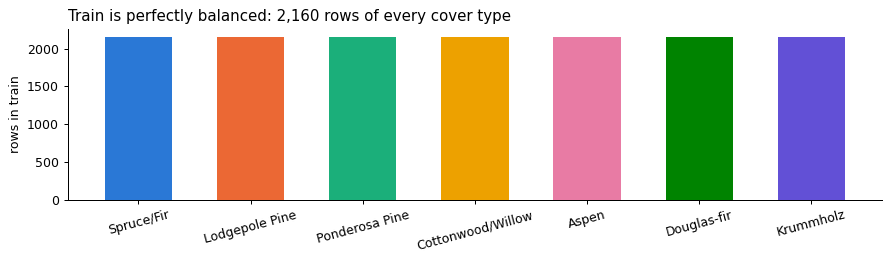

In [5]:
counts = train["Cover_Type"].map(COVER).value_counts().reindex(COVER.values())
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(counts.index, counts, color=[COLOR[c] for c in COVER], width=0.6)
ax.set_ylabel("rows in train"); ax.set_title("Train is perfectly balanced: 2,160 rows of every cover type", loc="left")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

- No missing values, no duplicates: no cleaning needed.
- Every row has exactly one wilderness area and one soil type, so the 44 binary columns are really **2 categorical columns**.
- Soil types 7 and 15 never appear in train: the model can learn nothing about them.
- Train is **balanced** (2,160 per class), so accuracy is a fair metric on it. The real forest is not balanced: step 9 deals with that.

## Step 4 · Explore: what separates the cover types?

### 4a · Elevation: each cover type has its own band

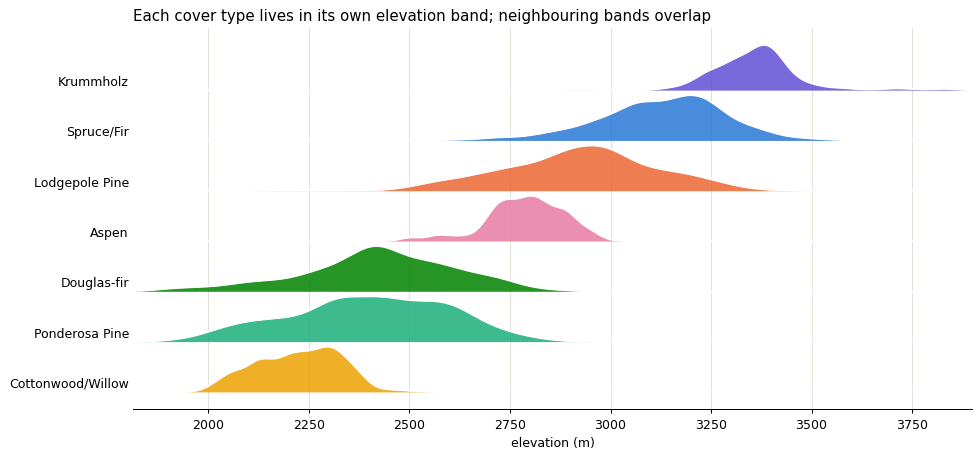

In [6]:
order = train.groupby("Cover_Type")["Elevation"].median().sort_values().index      # classes from low to high
grid = np.linspace(train["Elevation"].min() - 50, train["Elevation"].max() + 50, 400)
fig, ax = plt.subplots(figsize=(11, 5.2))
for k, c in enumerate(order):
    e = train.loc[train["Cover_Type"] == c, "Elevation"].to_numpy()
    width = 1.06 * e.std() * len(e) ** -0.2                                     # smoothing width (Silverman's rule)
    dens = np.exp(-0.5 * ((grid[:, None] - e[None, :]) / width) ** 2).sum(axis=1)
    ax.fill_between(grid, k, k + 0.9 * dens / dens.max(), color=COLOR[c], alpha=0.85, lw=0)
    ax.plot(grid, k + 0.9 * dens / dens.max(), color="white", lw=1.5)
ax.set_yticks([k + 0.2 for k in range(len(order))], [COVER[c] for c in order], fontsize=10)
ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
ax.set_xlim(grid[0], grid[-1]); ax.set_xlabel("elevation (m)")
ax.grid(axis="x", color="#e1e0d9"); ax.set_axisbelow(True)
ax.set_title("Each cover type lives in its own elevation band; neighbouring bands overlap", loc="left")
plt.tight_layout(); plt.show()

Elevation alone sorts the classes from Cottonwood/Willow (lowest) to Krummholz (highest). The bands overlap for two **hard pairs**: **Spruce/Fir vs. Lodgepole Pine**, and **Ponderosa Pine vs. Douglas-fir**. Everything else in the data is for telling those apart.

### 4b · Every numeric column, per cover type

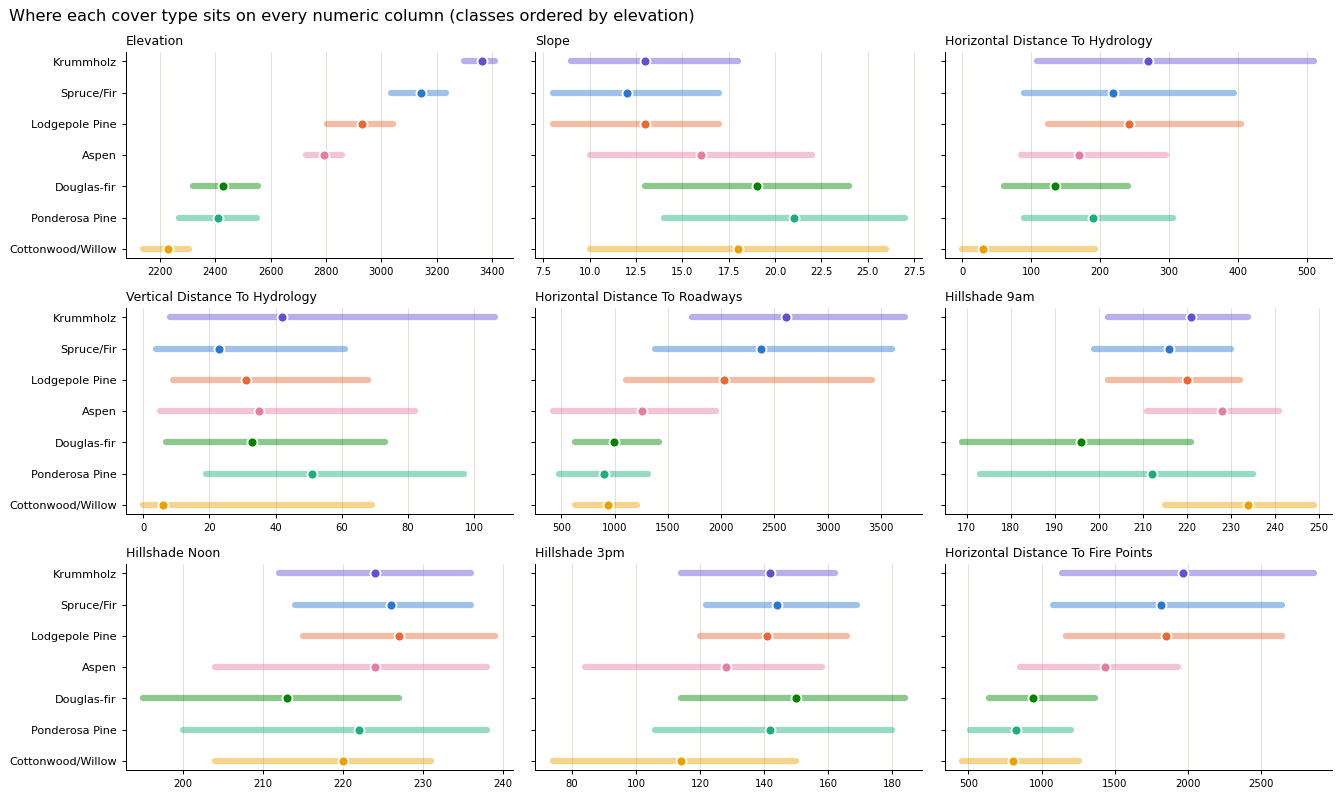

In [7]:
# dot = median, bar = middle 50% of the cells (25th to 75th percentile); aspect is shown on a compass in 4c
fig, axes = plt.subplots(3, 3, figsize=(15, 9), sharey=True)
for ax, col in zip(axes.ravel(), [c for c in NUMERIC if c != "Aspect"]):
    for k, c in enumerate(order):
        q1, med, q3 = train.loc[train["Cover_Type"] == c, col].quantile([0.25, 0.5, 0.75])
        ax.plot([q1, q3], [k, k], color=COLOR[c], lw=5, solid_capstyle="round", alpha=0.45)
        ax.plot(med, k, "o", color=COLOR[c], ms=8, mec="white", mew=1.5)
    ax.set_title(col.replace("_", " "), fontsize=10, loc="left")
    ax.grid(axis="x", color="#e1e0d9"); ax.set_axisbelow(True); ax.tick_params(axis="x", labelsize=8)
for ax in axes[:, 0]:
    ax.set_yticks(range(len(order)), [COVER[c] for c in order], fontsize=9)
fig.suptitle("Where each cover type sits on every numeric column (classes ordered by elevation)", x=0.01, ha="left", fontsize=13)
plt.tight_layout(); plt.show()

- **Distances to roads and fire points** also split the low classes from the high ones, with much more overlap than elevation.
- **Cottonwood/Willow** sits right next to water (smallest horizontal distance).
- **Douglas-fir** gets the least morning sun: a clue about which way its slopes face.

### 4c · Which way the slopes face

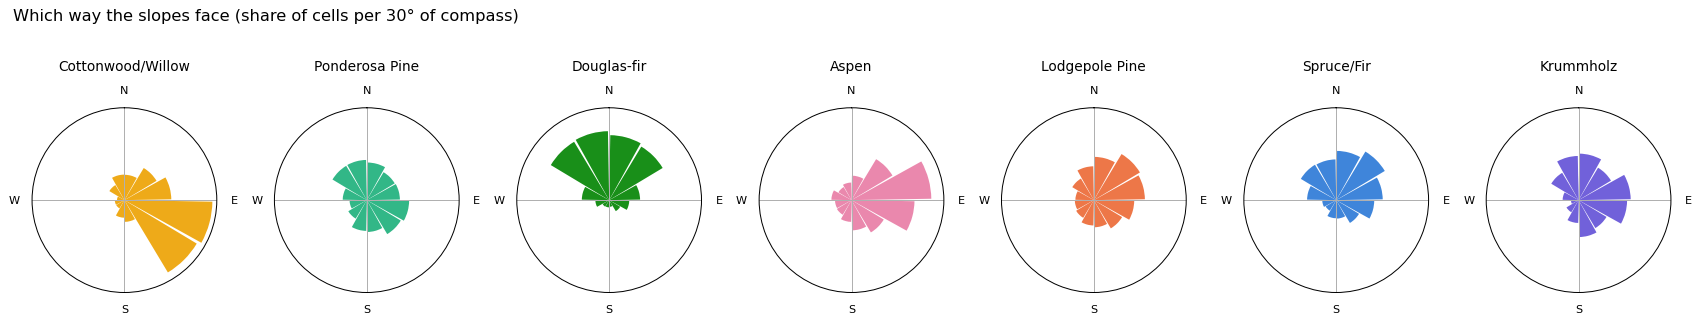

In [8]:
bins = np.radians(np.arange(0, 361, 30))
shares = {c: np.histogram(np.radians(train.loc[train["Cover_Type"] == c, "Aspect"] % 360), bins=bins)[0] for c in order}
shares = {c: s / s.sum() for c, s in shares.items()}
top = max(s.max() for s in shares.values()) * 1.05                       # same scale in every panel
fig, axes = plt.subplots(1, 7, figsize=(19, 3.6), subplot_kw={"projection": "polar"})
for ax, c in zip(axes, order):
    ax.bar(bins[:-1] + np.radians(15), shares[c], width=np.radians(28), color=COLOR[c], alpha=0.9)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)          # compass: north up, clockwise
    ax.set_xticks(np.radians([0, 90, 180, 270]), ["N", "E", "S", "W"], fontsize=9)
    ax.set_yticks([]); ax.set_ylim(0, top); ax.set_title(COVER[c], fontsize=11, pad=12)
fig.suptitle("Which way the slopes face (share of cells per 30° of compass)", x=0.01, ha="left", fontsize=13, y=1.04)
plt.tight_layout(); plt.show()

**Douglas-fir grows on north-facing slopes**, which get the least sun: that separates it from Ponderosa Pine at the same elevation. Note that aspect is an **angle**: 0° and 360° are both north.

### 4d · Pairs of columns: where each cover type lives

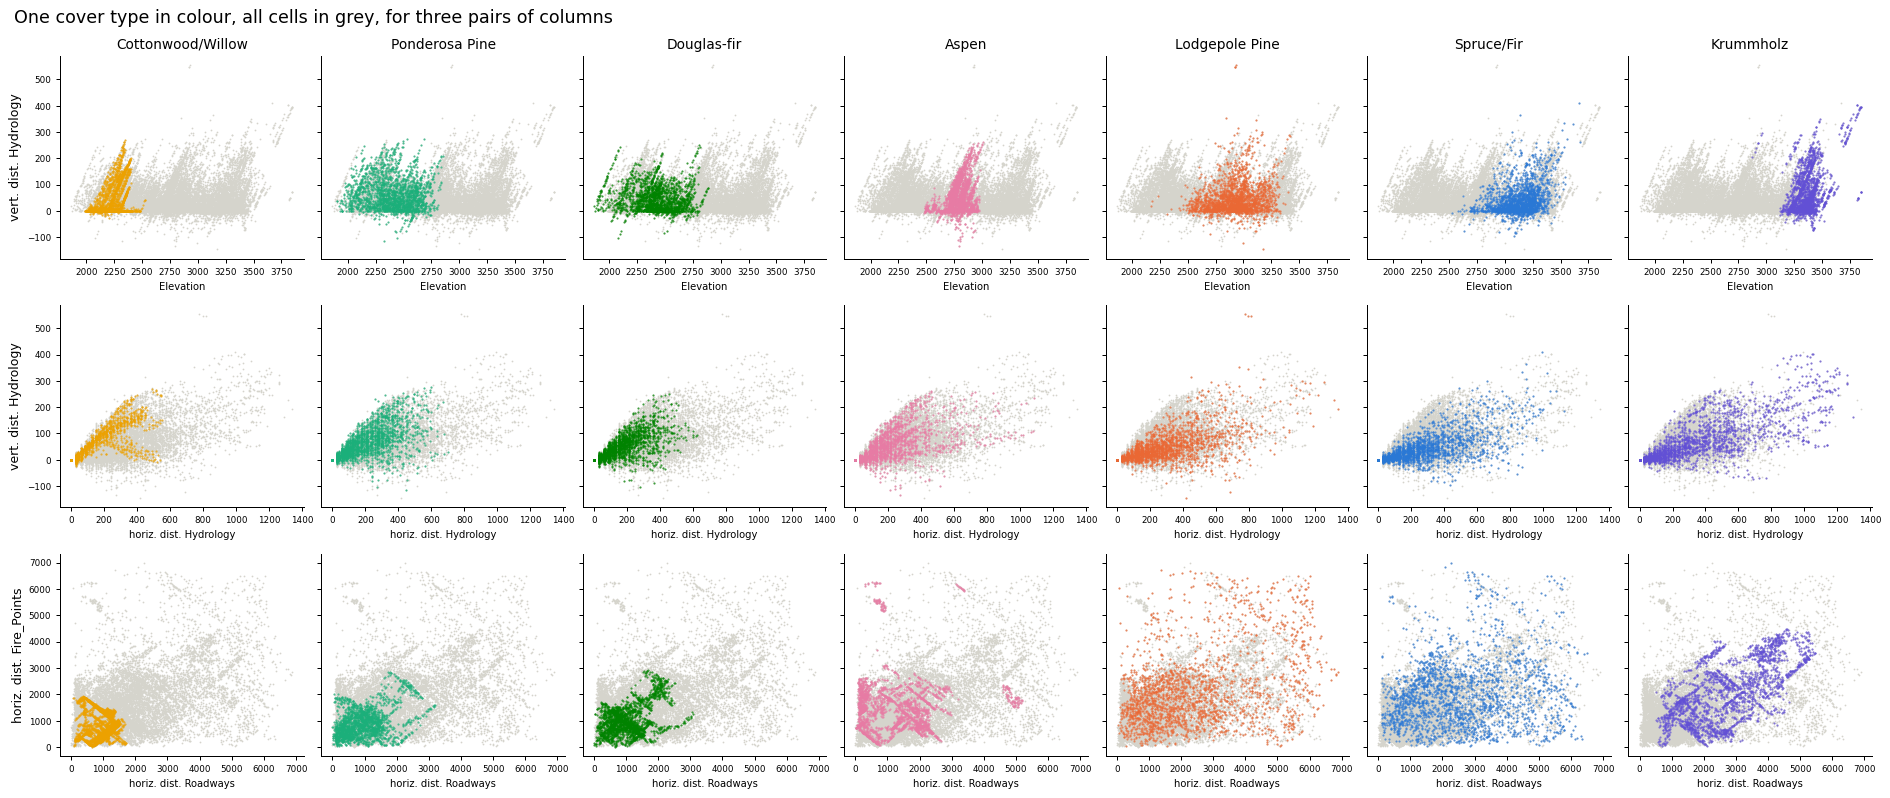

In [9]:
PAIRS = [("Elevation", "Vertical_Distance_To_Hydrology"),
         ("Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology"),
         ("Horizontal_Distance_To_Roadways", "Horizontal_Distance_To_Fire_Points")]
short = lambda col: col.replace("Horizontal_Distance_To_", "horiz. dist. ").replace("Vertical_Distance_To_", "vert. dist. ")
fig, axes = plt.subplots(len(PAIRS), 7, figsize=(21, 9), sharex="row", sharey="row")
for row, (x, y) in zip(axes, PAIRS):
    for ax, c in zip(row, order):
        ax.scatter(train[x], train[y], s=2, color="#d5d4cc", lw=0, rasterized=True)          # all cells, grey
        mine = train["Cover_Type"] == c
        ax.scatter(train.loc[mine, x], train.loc[mine, y], s=3, color=COLOR[c], lw=0, alpha=0.7, rasterized=True)
        ax.tick_params(labelsize=7); ax.set_xlabel(short(x), fontsize=8)
    row[0].set_ylabel(short(y), fontsize=10)
for ax, c in zip(axes[0], order):
    ax.set_title(COVER[c], fontsize=11)
fig.suptitle("One cover type in colour, all cells in grey, for three pairs of columns", x=0.01, ha="left", fontsize=14)
plt.tight_layout(); plt.show()

- **Row 1:** each class forms a band that **leans diagonally**. A diagonal means a *combination* of the two columns separates better than either one: `Elevation − Vertical_Distance_To_Hydrology` is the elevation of the nearest water.
- **Row 2:** Cottonwood/Willow hugs the corner close to water.
- **Row 3:** each class occupies its own region: the distances to roads and fire points act like map coordinates, and sums and differences of them can separate regions that the raw columns can't.

Decision trees can only split on one column at a time, so a diagonal boundary costs them many small steps. **Giving them the combination as a new column** is the feature engineering in step 5.

### 4e · How the columns relate to each other

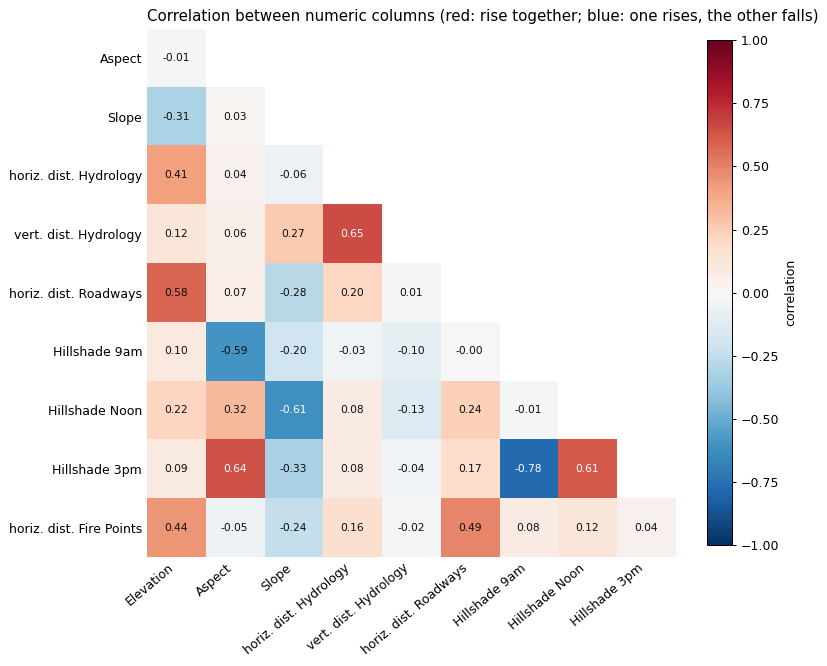

In [10]:
corr = train[NUMERIC].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(np.ma.masked_where(np.triu(np.ones_like(corr, dtype=bool)), corr), cmap="RdBu_r", vmin=-1, vmax=1)
for (i, j), v in np.ndenumerate(corr.to_numpy()):
    if i > j:
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.6 else "#0b0b0b")
labels = [short(c).replace("_", " ") for c in NUMERIC]
ax.set_xticks(range(len(NUMERIC) - 1), labels[:-1], rotation=40, ha="right"); ax.set_xlim(-0.5, len(NUMERIC) - 1.5)
ax.set_yticks(range(1, len(NUMERIC)), labels[1:]); ax.set_ylim(len(NUMERIC) - 0.5, 0.5)
ax.spines[:].set_visible(False); ax.tick_params(length=0)
plt.colorbar(im, fraction=0.04, label="correlation")
ax.set_title("Correlation between numeric columns (red: rise together; blue: one rises, the other falls)", loc="left")
plt.tight_layout(); plt.show()

The three hillshade columns correlate strongly with aspect and slope, and with each other: they are computed from the terrain, so they add little new information. No pair is a duplicate, so we keep every column; trees cope well with redundant columns.

### 4f · Wilderness area and soil

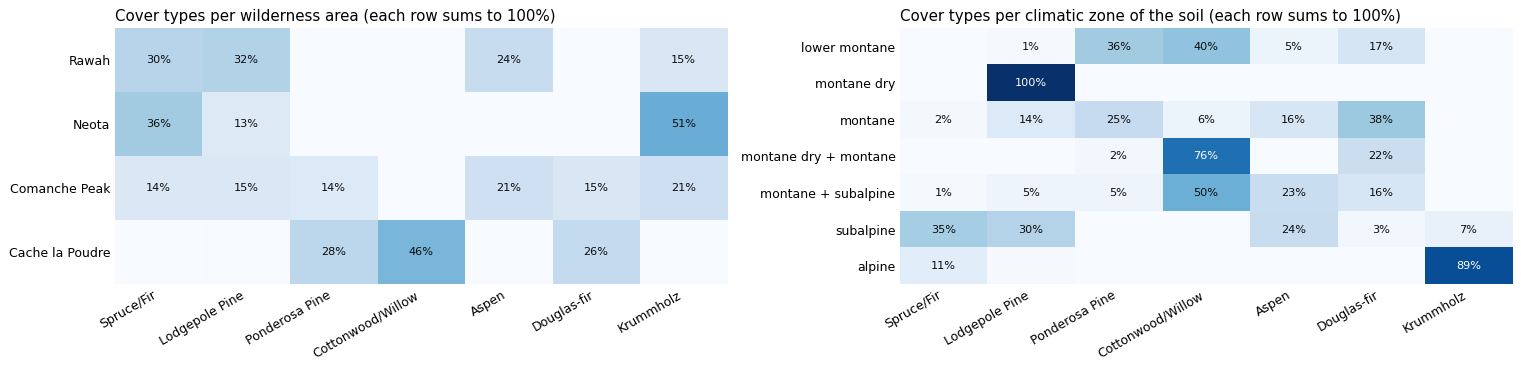

In [11]:
train["climate_zone"] = [ELU[i] // 1000 for i in train[SOIL].to_numpy().argmax(axis=1)]
tables = {"wilderness area": pd.crosstab(train[WILDERNESS].to_numpy().argmax(axis=1) + 1, train["Cover_Type"]).rename(index=AREA),
          "climatic zone of the soil": pd.crosstab(train["climate_zone"], train["Cover_Type"]).rename(index=CLIMATE)}
train = train.drop(columns="climate_zone")
fig, axes = plt.subplots(1, 2, figsize=(17, 4.2))
for ax, (name, t) in zip(axes, tables.items()):
    share = t.div(t.sum(axis=1), axis=0)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for (i, j), v in np.ndenumerate(share.to_numpy()):
        if v >= 0.01:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v > 0.55 else "#0b0b0b")
    ax.set_xticks(range(7), [COVER[c] for c in t.columns], rotation=30, ha="right")
    ax.set_yticks(range(len(t)), t.index); ax.spines[:].set_visible(False); ax.tick_params(length=0)
    ax.set_title(f"Cover types per {name} (each row sums to 100%)", loc="left")
plt.tight_layout(); plt.show()

- **Cache la Poudre** holds all the Cottonwood/Willow and most of the Ponderosa Pine and Douglas-fir; **Neota** has only high-elevation classes.
- The soil's **climatic zone** sorts the classes like elevation: alpine soils carry Krummholz, lower-montane soils the low classes.

## Step 5 · Feature engineering

Each new column comes from something step 4 showed. Trees need **no scaling or normalisation**, so we don't scale.

| New column | Formula | Why |
|---|---|---|
| `water_elevation` | Elevation − Vertical_Distance_To_Hydrology | the elevation of the nearest water: the diagonal bands in 4d, row 1 |
| `Hydrology_plus_Roadways` and five similar columns | sums and differences of the three horizontal distances | the distances act like map coordinates (4d, row 3); sums and differences cut the map diagonally |
| `elevation_minus_road` | Elevation − 0.02 × Horizontal_Distance_To_Roadways | elevation adjusted for distance from the road |
| `elevation_minus_water` | Elevation − 0.2 × Horizontal_Distance_To_Hydrology | elevation adjusted for distance from water |

These are the combinations that improved accuracy on unseen forest areas when tested one by one.

In [12]:
def add_features(d):
    """Raw columns plus the engineered combinations. Works the same on train and test."""
    X = d[RAW].astype(float).copy()
    X["water_elevation"] = d["Elevation"] - d["Vertical_Distance_To_Hydrology"]
    for a, b in [("Hydrology", "Roadways"), ("Hydrology", "Fire_Points"), ("Fire_Points", "Roadways")]:
        A, B = d[f"Horizontal_Distance_To_{a}"], d[f"Horizontal_Distance_To_{b}"]
        X[f"{a}_plus_{b}"], X[f"{a}_minus_{b}"] = A + B, A - B
    X["elevation_minus_road"] = d["Elevation"] - 0.02 * d["Horizontal_Distance_To_Roadways"]
    X["elevation_minus_water"] = d["Elevation"] - 0.2 * d["Horizontal_Distance_To_Hydrology"]
    return X

X_all, y_all = add_features(train), train["Cover_Type"].to_numpy()
print(f"{X_all.shape[1]} columns: {len(RAW)} raw + {X_all.shape[1] - len(RAW)} engineered")
X_all.iloc[:3, len(RAW):]

63 columns: 54 raw + 9 engineered


,water_elevation,Hydrology_plus_Roadways,Hydrology_minus_Roadways,Hydrology_plus_Fire_Points,Hydrology_minus_Fire_Points,Fire_Points_plus_Roadways,Fire_Points_minus_Roadways,elevation_minus_road,elevation_minus_water
0,2596,768,-252,6537,-6021,6789,5769,2585.8,2544.4
1,2596,602,-178,6437,-6013,6615,5835,2582.2,2547.6
2,2739,3448,-2912,6389,-5853,9301,2941,2740.4,2750.4


## Step 6 · Hold out a test set of unseen forest areas

The rows of `train.csv` are stored in **map order**: neighbouring rows are neighbouring cells and almost identical. If we picked random rows for testing, every test row would have a near-copy in training, and the score would look better than it is on new terrain.

So we cut the rows into **blocks of 200 consecutive rows** (each block is one area of the forest) and hold out **20% of the blocks**. The model is tested on areas of the forest it has never seen.

In [13]:
blocks = np.arange(len(train)) // 200
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X_all, groups=blocks))
X_train, X_test, y_train, y_test = X_all.iloc[train_idx], X_all.iloc[test_idx], y_all[train_idx], y_all[test_idx]
print(f"training rows: {len(X_train):,} | held-out rows: {len(X_test):,} (from {len(set(blocks[test_idx]))} unseen areas)")

training rows: 12,000 | held-out rows: 3,120 (from 16 unseen areas)


## Step 7 · Train and evaluate the model

**Extra trees** (extremely randomised trees): an ensemble of hundreds of decision trees, each grown with random split points; the forest votes. It's fast, needs no scaling, and handles the mix of numeric and 0/1 columns. We use scikit-learn's default settings: on this data, tuning them gave no reliable gain.

In [14]:
model = ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print(f"accuracy on unseen forest areas: {accuracy_score(y_test, pred):.1%}  (guessing: {1/7:.1%})\n")
print(classification_report(y_test, pred, target_names=COVER.values(), digits=3))

accuracy on unseen forest areas: 83.7%  (guessing: 14.3%)

                   precision    recall  f1-score   support

       Spruce/Fir      0.772     0.803     0.787       523
   Lodgepole Pine      0.797     0.662     0.724       480
   Ponderosa Pine      0.855     0.779     0.815       544
Cottonwood/Willow      0.935     0.977     0.956       222
            Aspen      0.864     0.942     0.902       521
      Douglas-fir      0.788     0.858     0.822       408
        Krummholz      0.897     0.929     0.913       422

         accuracy                          0.837      3120
        macro avg      0.844     0.850     0.845      3120
     weighted avg      0.836     0.837     0.835      3120



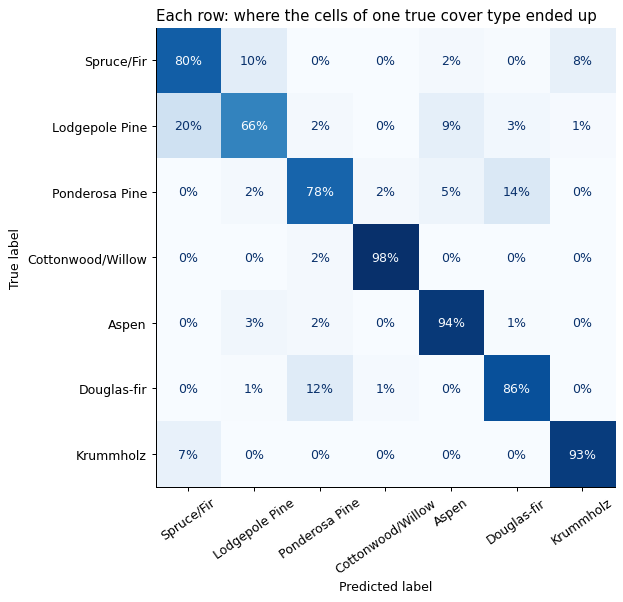

In [15]:
fig, ax = plt.subplots(figsize=(8, 6.8))
ConfusionMatrixDisplay.from_predictions(pd.Series(y_test).map(COVER), pd.Series(pred).map(COVER), labels=list(COVER.values()),
                                        normalize="true", values_format=".0%", cmap="Blues", colorbar=False,
                                        xticks_rotation=35, ax=ax)
ax.set_title("Each row: where the cells of one true cover type ended up", loc="left")
plt.tight_layout(); plt.show()

How to read it: the diagonal is the share of each cover type predicted correctly (its recall). The off-diagonal cells show the mistakes, and they sit where step 4 predicted: **Spruce/Fir ↔ Lodgepole Pine** and **Ponderosa Pine ↔ Douglas-fir**. Lodgepole Pine is the weakest class (a fifth of its cells are called Spruce/Fir); Cottonwood/Willow, Aspen and Krummholz are the easiest.

## Step 8 · Which features does the model use?

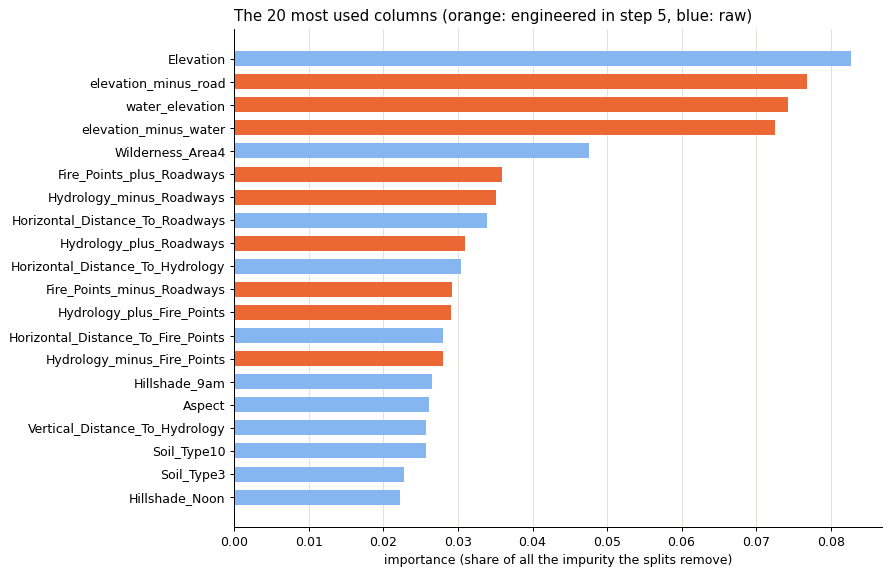

In [16]:
importance = pd.Series(model.feature_importances_, index=X_train.columns).sort_values().tail(20)
engineered = set(X_all.columns) - set(RAW)
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(importance.index, importance, color=["#eb6834" if c in engineered else "#86b6ef" for c in importance.index], height=0.65)
ax.set_xlabel("importance (share of all the impurity the splits remove)")
ax.set_title("The 20 most used columns (orange: engineered in step 5, blue: raw)", loc="left")
ax.grid(axis="x", color="#e1e0d9"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

The engineered columns rank at the top, next to elevation: the model prefers the combinations we gave it over the raw columns they're built from.

A caution: importance says **how much the model used a column**, not that the column causes the cover type, and correlated columns share their importance.

## Step 9 · Final model and predictions for Kaggle

1. **Retrain on all 15,120 rows**: the held-out areas were only for measuring; the final model should learn from everything.
2. **Adjust for the real forest mix.** Train is balanced, but the real forest isn't: about half the cells are Lodgepole Pine and very few are Cottonwood/Willow. A model trained on balanced data predicts the rare classes too often. We estimate the real class shares from the model's own predictions on the unlabelled test set (an EM procedure, Saerens et al. 2002), then weight the probabilities by them.
3. **Write `submission.csv`** in Kaggle's format: `Id`, `Cover_Type`.

In [17]:
final = ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_all, y_all)
X_kaggle = add_features(test)
proba = np.vstack([final.predict_proba(X_kaggle.iloc[i:i + 50_000])                      # in chunks to save memory
                   for i in range(0, len(X_kaggle), 50_000)])

# EM: find the class shares that make the predictions on the unlabelled test set self-consistent
shares = proba.mean(axis=0)
for _ in range(200):
    adjusted = proba * shares                       # training classes were balanced, so their share cancels out
    adjusted /= adjusted.sum(axis=1, keepdims=True)
    shares = adjusted.mean(axis=0)
predictions = final.classes_[(proba * shares).argmax(axis=1)]

pd.DataFrame({"training share": 1 / 7, "estimated share in the real forest": shares,
              "share of our predictions": pd.Series(predictions).value_counts(normalize=True).reindex(final.classes_, fill_value=0).to_numpy()},
             index=[COVER[c] for c in final.classes_]).style.format("{:.1%}")

,training share,estimated share in the real forest,share of our predictions
Spruce/Fir,14.3%,37.6%,36.0%
Lodgepole Pine,14.3%,50.1%,52.1%
Ponderosa Pine,14.3%,6.3%,6.4%
Cottonwood/Willow,14.3%,0.1%,0.0%
Aspen,14.3%,0.8%,0.5%
Douglas-fir,14.3%,2.3%,2.1%
Krummholz,14.3%,2.9%,2.8%


In [18]:
submission = pd.DataFrame({"Id": test_ids, "Cover_Type": predictions})
submission.to_csv("submission.csv", index=False)
print(f"saved submission.csv: {len(submission):,} rows")
display(submission.head())

try:                                                # in Colab: download the file to your computer
    from google.colab import files
    files.download("submission.csv")
except ImportError:
    pass

saved submission.csv: 565,892 rows


,Id,Cover_Type
0,15121,1
1,15122,1
2,15123,1
3,15124,1
4,15125,1


To score it, upload `submission.csv` on the competition's *Late Submission* page (https://www.kaggle.com/c/forest-cover-type-prediction).

---
## Summary

| Step | Key point |
|---|---|
| Data | 15,120 training cells, 54 columns = 12 measurements in 6 groups; clean, no missing values |
| Exploration | elevation does most of the work; the hard pairs are Spruce/Fir vs. Lodgepole Pine and Ponderosa Pine vs. Douglas-fir |
| Features | combinations that turn diagonal boundaries into single columns: water elevation, sums and differences of distances |
| Testing | hold out whole areas of the forest, because neighbouring rows are near-copies |
| Model | extra trees, 300 trees, default settings, no scaling |
| Predictions | retrained on all rows; probabilities adjusted to the real forest's class mix |

**Ideas to try next:** gradient boosting (e.g. LightGBM) and averaging it with extra trees; more combinations suggested by the scatter plots; checking each idea on the held-out forest areas before keeping it.